# 498R — Perception-blind confidence in chart VQA: Day 1 + Day 2
**Before running:** Session options → Accelerator = **GPU T4 x2**, Internet = **On**. Then run cells top to bottom.

- **Day 1:** Qwen2-VL-7B (4-bit) answers 500 ChartQA test questions, saving token log-probabilities.
- **Day 2:** three more confidence scores (sampling agreement, verbalized confidence) and the metrics (ECE, AUROC, risk-coverage).

Always use the same `--n 500` in every stage. Every stage resumes from its saved file if interrupted, so just rerun the same cell.

## 0. Setup

In [1]:
!nvidia-smi

Mon Nov 23 14:02:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   58C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# NOTE: pandas / scikit-learn / matplotlib are deliberately NOT upgraded (that caused an ImportError before).
# A pip 'dependency conflict' warning about cudf / bigframes / pyarrow is harmless - ignore it.
!pip install -q -U transformers accelerate bitsandbytes datasets

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [3]:
!python -c "import transformers, accelerate, bitsandbytes, datasets, pyarrow; print('transformers', transformers.__version__); print('bitsandbytes', bitsandbytes.__version__); print('datasets', datasets.__version__); print('ALL IMPORTS OK')"

transformers 5.24.0
bitsandbytes 0.50.2
datasets 5.2.0
ALL IMPORTS OK


## 1. The script (written to disk by this notebook, so no dataset upload is needed)

In [4]:
%%writefile /kaggle/working/pbc_day1_day2.py
"""
Perception-blind confidence (498R) -- Day 1 + Day 2 starter script.
Standalone: no RoSE code. Model: Qwen2-VL-7B-Instruct (4-bit). Data: ChartQA test subset.

Usage (Colab/Kaggle T4):
  pip install -q transformers accelerate bitsandbytes datasets scikit-learn matplotlib pandas
  python pbc_day1_day2.py greedy  --n 500     # Day 1: answers + token log-probs
  python pbc_day1_day2.py sample  --n 500     # Day 2: 5 sampled answers (agreement)
  python pbc_day1_day2.py verbal  --n 500     # Day 2: verbalized confidence
  python pbc_day1_day2.py analyze             # Day 2: ECE, AUROC, risk-coverage

Every stage appends to a .jsonl file and skips finished ids, so you can resume
after a Colab/Kaggle disconnect.
"""
import argparse, json, math, os, random, re
from pathlib import Path

OUT = Path(os.environ.get("PBC_RESULTS", "results")); OUT.mkdir(parents=True, exist_ok=True)
# Tip: set PBC_RESULTS to a Google Drive / persistent folder so a disconnect never loses data.
MODEL_ID = "Qwen/Qwen2-VL-7B-Instruct"
SEED = 0

# ---------------------------------------------------------------- scoring
def to_float(s):
    s = str(s).strip().replace(",", "").replace("$", "").replace("%", "")
    try:
        return float(s)
    except ValueError:
        return None

def relaxed_correct(pred, golds):
    """ChartQA relaxed accuracy: numeric within 5%, otherwise exact (case-insens.)."""
    for g in golds:
        pf, gf = to_float(pred), to_float(g)
        if pf is not None and gf is not None:
            ok = (pf == 0) if gf == 0 else abs(pf - gf) / abs(gf) <= 0.05
        else:
            ok = str(pred).strip().lower() == str(g).strip().lower()
        if ok:
            return True
    return False

def norm(s):
    f = to_float(s)
    return f"{f:.6g}" if f is not None else str(s).strip().lower()

# ---------------------------------------------------------------- data/model
def load_subset(n):
    from datasets import load_dataset
    ds = load_dataset("HuggingFaceM4/ChartQA", split="test")
    idx = list(range(len(ds)))
    random.Random(SEED).shuffle(idx)   # fixed order: --n 20 is always a prefix of --n 500
    return ds, idx[:n]

def load_model():
    import torch
    from transformers import (Qwen2VLForConditionalGeneration, AutoProcessor,
                              BitsAndBytesConfig)
    bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                             bnb_4bit_compute_dtype=torch.float16)  # T4: no bf16
    model = Qwen2VLForConditionalGeneration.from_pretrained(
        MODEL_ID, quantization_config=bnb, torch_dtype=torch.float16, device_map="auto")
    # lower max_pixels if you hit out-of-memory
    proc = AutoProcessor.from_pretrained(MODEL_ID, min_pixels=256*28*28, max_pixels=768*28*28)
    model.eval()
    return model, proc

def build_inputs(proc, image, text):
    msgs = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": text}]}]
    prompt = proc.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    return proc(text=[prompt], images=[image.convert("RGB")], return_tensors="pt").to("cuda")

def done_ids(path):
    if not path.exists():
        return set()
    return {json.loads(l)["id"] for l in open(path)}

def summarize(path):
    recs = [json.loads(l) for l in open(path)]
    msg = f"\nDONE: {path.name} now has {len(recs)} records"
    if recs and "correct" in recs[0]:
        msg += f", accuracy={sum(r['correct'] for r in recs) / len(recs):.3f}"
    print(msg, flush=True)

def stop_ids(proc):
    tok = proc.tokenizer
    ids = {tok.eos_token_id}
    im_end = tok.convert_tokens_to_ids("<|im_end|>")
    if im_end is not None:
        ids.add(im_end)
    return ids

# ---------------------------------------------------------------- Day 1
def run_greedy(n):
    import torch
    ds, idx = load_subset(n)
    model, proc = load_model()
    stops = stop_ids(proc)
    path = OUT / "greedy.jsonl"; done = done_ids(path)
    with open(path, "a") as f:
        for k, i in enumerate(idx):
            if i in done:
                continue
            ex = ds[i]
            q, golds = ex["query"], ex["label"]
            inp = build_inputs(proc, ex["image"], q + "\nAnswer the question using a single word or phrase.")
            with torch.no_grad():
                out = model.generate(**inp, max_new_tokens=32, do_sample=False,
                                     repetition_penalty=1.0,  # keep probabilities clean
                                     return_dict_in_generate=True, output_logits=True)
            gen = out.sequences[0, inp["input_ids"].shape[1]:].tolist()
            lps, toks = [], []
            for t, tok in enumerate(gen):
                if tok in stops:
                    break
                lp = torch.log_softmax(out.logits[t][0].float(), -1)[tok].item()
                lps.append(lp); toks.append(tok)
            ans = proc.tokenizer.decode(toks, skip_special_tokens=True).strip()
            rec = dict(id=i, question=q, golds=golds, answer=ans,
                       correct=relaxed_correct(ans, golds),
                       human_or_machine=ex.get("human_or_machine"),
                       token_logprobs=lps)
            f.write(json.dumps(rec) + "\n"); f.flush()
            if k % 5 == 0:
                print(f"{k}/{len(idx)}  last: {ans!r} correct={rec['correct']}")
    summarize(path)

# ---------------------------------------------------------------- Day 2
def run_sample(n, k_samples=5):
    import torch
    ds, idx = load_subset(n)
    greedy = {json.loads(l)["id"]: json.loads(l) for l in open(OUT / "greedy.jsonl")}
    model, proc = load_model()
    path = OUT / "sample.jsonl"; done = done_ids(path)
    with open(path, "a") as f:
        for i in idx:
            if i in done or i not in greedy:
                continue
            ex = ds[i]
            inp = build_inputs(proc, ex["image"], ex["query"] + "\nAnswer the question using a single word or phrase.")
            with torch.no_grad():
                out = model.generate(**inp, max_new_tokens=32, do_sample=True, temperature=0.7,
                                     top_p=1.0, top_k=0, repetition_penalty=1.0,
                                     num_return_sequences=k_samples)
            outs = proc.tokenizer.batch_decode(out[:, inp["input_ids"].shape[1]:],
                                               skip_special_tokens=True)
            outs = [o.strip() for o in outs]
            g = norm(greedy[i]["answer"])
            agree = sum(norm(o) == g for o in outs) / k_samples
            f.write(json.dumps(dict(id=i, samples=outs, agreement=agree)) + "\n"); f.flush()
            print(".", end="", flush=True)
    summarize(path)

def run_verbal(n):
    import torch
    ds, idx = load_subset(n)
    greedy = {json.loads(l)["id"]: json.loads(l) for l in open(OUT / "greedy.jsonl")}
    model, proc = load_model()
    path = OUT / "verbal.jsonl"; done = done_ids(path)
    with open(path, "a") as f:
        for i in idx:
            if i in done or i not in greedy:
                continue
            ex = ds[i]
            text = (f"Question: {ex['query']}\nProposed answer: {greedy[i]['answer']}\n"
                    "How confident are you that the proposed answer is correct? "
                    "Reply with only a number from 0 to 100.")
            inp = build_inputs(proc, ex["image"], text)
            with torch.no_grad():
                out = model.generate(**inp, max_new_tokens=6, do_sample=False, repetition_penalty=1.0)
            raw = proc.tokenizer.decode(out[0, inp["input_ids"].shape[1]:], skip_special_tokens=True)
            m = re.search(r"\d+(\.\d+)?", raw)
            conf = min(float(m.group()), 100.0) / 100 if m else None
            f.write(json.dumps(dict(id=i, raw=raw, verbal=conf)) + "\n"); f.flush()
            print(".", end="", flush=True)
    summarize(path)

# ---------------------------------------------------------------- metrics
def ece(conf, correct, bins=15):
    import numpy as np
    conf, correct = np.asarray(conf, float), np.asarray(correct, float)
    edges = np.linspace(0, 1, bins + 1)
    total = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi) if lo > 0 else (conf >= lo) & (conf <= hi)
        if m.any():
            total += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return total

def risk_coverage(conf, correct):
    import numpy as np
    order = np.argsort(-np.asarray(conf, float), kind="stable")
    c = np.asarray(correct, float)[order]
    n = len(c)
    coverage = np.arange(1, n + 1) / n
    risk = 1 - np.cumsum(c) / np.arange(1, n + 1)
    return coverage, risk, risk.mean()  # mean risk over coverage = AURC

def analyze():
    import numpy as np, pandas as pd, matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from sklearn.metrics import roc_auc_score
    g = pd.DataFrame([json.loads(l) for l in open(OUT / "greedy.jsonl")])
    lp = g["token_logprobs"].apply(lambda x: x if len(x) else [-20.0])
    g["seq_prob"] = lp.apply(lambda x: math.exp(sum(x)))
    g["min_prob"] = lp.apply(lambda x: math.exp(min(x)))
    g["mean_prob"] = lp.apply(lambda x: math.exp(sum(x) / len(x)))
    for name, col in [("sample", "agreement"), ("verbal", "verbal")]:
        p = OUT / f"{name}.jsonl"
        if p.exists():
            d = pd.DataFrame([json.loads(l) for l in open(p)])[["id", col]]
            g = g.merge(d, on="id", how="left")
    if "verbal" in g:
        print(f"verbal parse failures: {g['verbal'].isna().sum()} / {len(g)} (filled with 0.5)")
        g["verbal"] = g["verbal"].fillna(0.5)
    scores = [c for c in ["seq_prob", "min_prob", "mean_prob", "agreement", "verbal"] if c in g]
    y = g["correct"].astype(int).values
    print(f"\nN={len(g)}  accuracy={y.mean():.3f}")
    g["split"] = g["human_or_machine"].map({0: "human", 1: "machine"}).fillna("unknown")
    print(g.groupby("split")["correct"].agg(["mean", "count"]).round(3).to_string())
    rows, fig, ax = [], plt.figure(figsize=(6, 4)), plt.gca()
    for s in scores:
        cov, risk, aurc = risk_coverage(g[s], y)
        ax.plot(cov, risk, label=s)
        auc = roc_auc_score(y, g[s]) if len(set(y)) > 1 else float("nan")
        rows.append(dict(score=s, ECE=ece(g[s], y), AUROC=auc, AURC=aurc))
    ax.set_xlabel("coverage"); ax.set_ylabel("risk (error rate)"); ax.legend()
    fig.tight_layout(); fig.savefig(OUT / "risk_coverage.png", dpi=150)
    table = pd.DataFrame(rows).round(3); print(table.to_string(index=False))
    table.to_csv(OUT / "baseline_table.csv", index=False)
    # reliability diagram for the sequence probability
    edges = np.linspace(0, 1, 11); mids, accs = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (g["seq_prob"] > lo) & (g["seq_prob"] <= hi)
        if m.any():
            mids.append(g.loc[m, "seq_prob"].mean()); accs.append(y[m.values].mean())
    plt.figure(figsize=(4, 4)); plt.plot([0, 1], [0, 1], "--", c="gray")
    plt.plot(mids, accs, "o-"); plt.xlabel("confidence (seq_prob)"); plt.ylabel("accuracy")
    plt.tight_layout(); plt.savefig(OUT / "reliability_seq_prob.png", dpi=150)
    g.to_csv(OUT / "merged.csv", index=False)
    print("\nSaved: baseline_table.csv, risk_coverage.png, reliability_seq_prob.png, merged.csv")

if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("stage", choices=["greedy", "sample", "verbal", "analyze"])
    ap.add_argument("--n", type=int, default=500)
    a = ap.parse_args()
    {"greedy": lambda: run_greedy(a.n), "sample": lambda: run_sample(a.n),
     "verbal": lambda: run_verbal(a.n), "analyze": analyze}[a.stage]()

Writing /kaggle/working/pbc_day1_day2.py


In [5]:
import os
os.chdir("/kaggle/working")
os.makedirs("/kaggle/working/results", exist_ok=True)
print("script present:", os.path.exists("pbc_day1_day2.py"))
print("new version (has DONE messages):", "summarize" in open("pbc_day1_day2.py").read())

script present: True
new version (has DONE messages): True


In [6]:
# What results already exist? (an error from wc just means none yet - that is fine)
!ls -la /kaggle/working/results
!wc -l /kaggle/working/results/*.jsonl

total 8
drwxr-xr-x 2 root root 4096 Nov 23 14:02 .
drwxr-xr-x 3 root root 4096 Nov 23 14:02 ..
wc: '/kaggle/working/results/*.jsonl': No such file or directory


## 2. Day 1 — answers + token log-probabilities (about 30-45 min)
If you only want a quick test first, change `--n 500` to `--n 20` (the 20 questions are a prefix of the 500, so nothing is wasted).

In [7]:
!CUDA_VISIBLE_DEVICES=0 PBC_RESULTS=/kaggle/working/results python pbc_day1_day2.py greedy --n 500

README.md: 100%|███████████████████████████████| 852/852 [00:00<00:00, 5.57MB/s]

data/train-00000-of-00003-49492f364babfa(…): downloading bytes: ▍| 88.6MB, 6.48M
data/train-00000-of-00003-49492f364babfa(…): downloading bytes: ▌|  121MB, 9.93M
data/train-00000-of-00003-49492f364babfa(…): downloading bytes: ▋|  145MB, 12.7M
data/train-00000-of-00003-49492f364babfa(…): downloading bytes: ▊|  175MB, 14.4M
data/train-00000-of-00003-49492f364babfa(…): reconstructing file:  58%|▌|  126MB
data/train-00000-of-00003-49492f364babfa(…): downloading bytes: ▉|  196MB, 16.7M
data/train-00000-of-00003-49492f364babfa(…): downloading bytes: █|  213MB, 18.8M
data/train-00000-of-00003-49492f364babfa(…): reconstructing file: 100%|█|  219MB

data/train-00001-of-00003-7302bae5e425bb(…): downloading bytes: ▏| 54.7MB, 2.08M
data/train-00001-of-00003-7302bae5e425bb(…): downloading bytes: ▍|  150MB, 9.99M
data/train-00001-of-00003-7302bae5e425bb(…): downloading bytes: ▊|  244MB, 18.7M
data/train-00001-of-00003-

**Gate 2 check:** expect 500 rows and accuracy roughly in the 70s to low 80s. Below 50% = stop and debug.

In [8]:
import pandas as pd
g = pd.read_json("/kaggle/working/results/greedy.jsonl", lines=True)
print("rows:", len(g), " accuracy:", round(g.correct.mean(), 3))
print(g.groupby("human_or_machine").correct.agg(["mean", "count"]))
print("max token log-prob (should be <= 0):", g.token_logprobs.apply(lambda x: max(x) if x else None).max())
print(g[["question", "answer", "golds", "correct"]].head(10).to_string())

rows: 500  accuracy: 0.834
                      mean  count
human_or_machine                 
0                 0.723577    246
1                 0.940945    254
max token log-prob (should be <= 0): 0.0
                                                                                                      question          answer             golds  correct
0                                                                   What country does the green bar represent?        Bulgaria        [Bulgaria]     True
1                                                                 How many categories are there in the chart??               4               [4]     True
2                                          What is the sum of highest value and lowest value of navy blue bar?          2482.3          [2372.1]     True
3                                                             What is the most popular social media for women?        Facebook        [WhatsApp]    False
4                         

In [9]:
!cd /kaggle/working && zip -rq results.zip results && ls -la results.zip   # then download it from the right panel: Data -> Output

-rw-r--r-- 1 root root 39070 Nov 23 14:18 results.zip


## 3. Day 2 — sampling agreement (about 1 hour) and verbalized confidence (about 20-30 min)
These run one after another (safe, and works with *Save & Run All*).

In [10]:
!CUDA_VISIBLE_DEVICES=0 PBC_RESULTS=/kaggle/working/results python pbc_day1_day2.py sample --n 500

Loading weights: 100%|████████████████████████| 730/730 [00:17<00:00, 42.78it/s]
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
....................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................
DONE: sample.jsonl now has 500 records


In [11]:
!CUDA_VISIBLE_DEVICES=0 PBC_RESULTS=/kaggle/working/results python pbc_day1_day2.py verbal --n 500

Loading weights: 100%|████████████████████████| 730/730 [00:14<00:00, 50.30it/s]
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
....................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................
DONE: verbal.jsonl now has 500 records


In [12]:
# Check parse failures for verbalized confidence: if more than ~20% are empty, the prompt needs adjusting
import pandas as pd
v = pd.read_json("/kaggle/working/results/verbal.jsonl", lines=True)
print("rows:", len(v), " failed to parse:", int(v.verbal.isna().sum()))
print(v.raw.value_counts().head(8))

rows: 500  failed to parse: 0
raw
100.0    135
80.0     127
90.0     123
50.0      34
60.0      10
85.0       9
70.0       5
88.0       3
Name: count, dtype: int64


### (Optional, interactive sessions only) Run sampling and verbal at the same time on the two GPUs
Skip this if you already ran the two cells above. Uncomment the two lines, run, then use the progress cell. Do **not** use with *Save & Run All*.

In [13]:
# !CUDA_VISIBLE_DEVICES=0 PBC_RESULTS=/kaggle/working/results nohup python pbc_day1_day2.py sample --n 500 > sample.log 2>&1 &
# !CUDA_VISIBLE_DEVICES=1 PBC_RESULTS=/kaggle/working/results nohup python pbc_day1_day2.py verbal --n 500 > verbal.log 2>&1 &

In [14]:
!tail -c 300 sample.log; echo; echo ---; tail -c 300 verbal.log; echo; wc -l results/*.jsonl   # progress check (optional)

tail: cannot open 'sample.log' for reading: No such file or directory

---
tail: cannot open 'verbal.log' for reading: No such file or directory

   500 results/greedy.jsonl
   500 results/sample.jsonl
   500 results/verbal.jsonl
  1500 total


## 4. Analysis — ECE, AUROC, risk-coverage

In [15]:
!PBC_RESULTS=/kaggle/working/results python pbc_day1_day2.py analyze

verbal parse failures: 0 / 500 (filled with 0.5)

N=500  accuracy=0.834
          mean  count
split                
human    0.724    246
machine  0.941    254
    score   ECE  AUROC  AURC
 seq_prob 0.070  0.854 0.045
 min_prob 0.042  0.857 0.045
mean_prob 0.061  0.871 0.041
agreement 0.106  0.767 0.075
   verbal 0.088  0.612 0.128

Saved: baseline_table.csv, risk_coverage.png, reliability_seq_prob.png, merged.csv


    score   ECE  AUROC  AURC
 seq_prob 0.070  0.854 0.045
 min_prob 0.042  0.857 0.045
mean_prob 0.061  0.871 0.041
agreement 0.106  0.767 0.075
   verbal 0.088  0.612 0.128


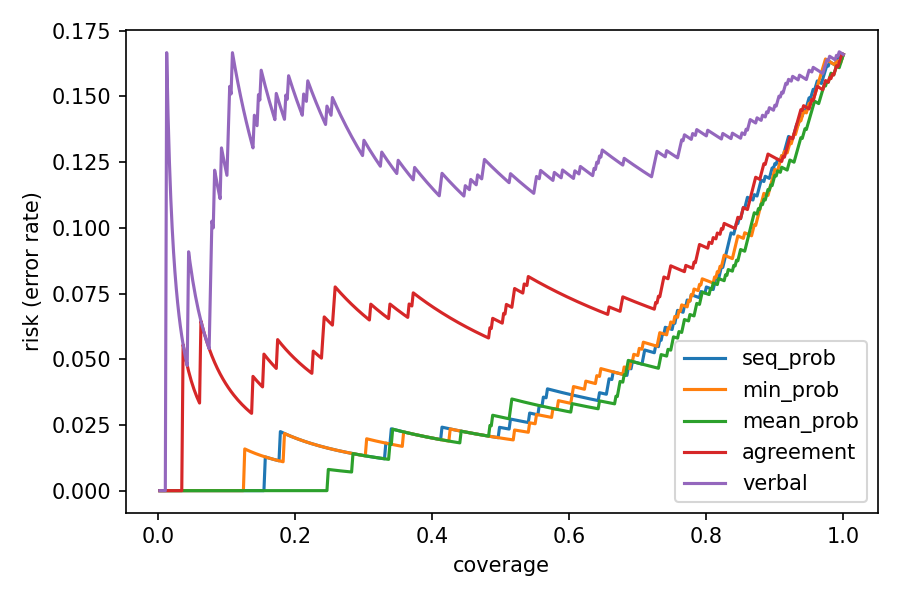

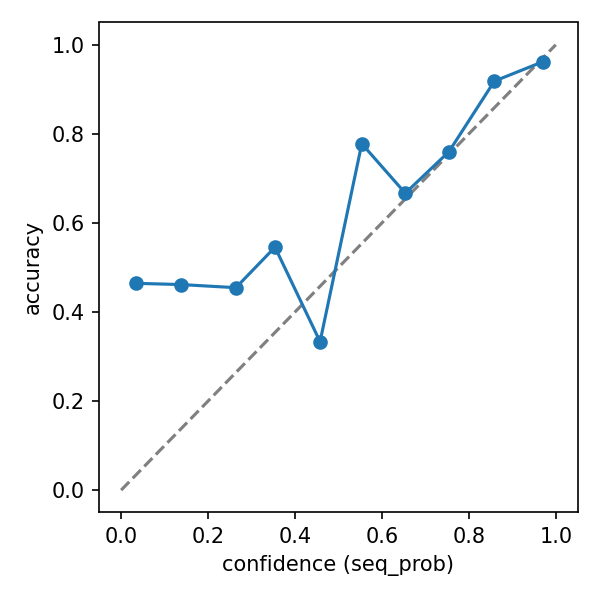

In [16]:
import pandas as pd
from IPython.display import Image, display
print(pd.read_csv("/kaggle/working/results/baseline_table.csv").to_string(index=False))
display(Image("/kaggle/working/results/risk_coverage.png"))
display(Image("/kaggle/working/results/reliability_seq_prob.png"))

In [17]:
!cd /kaggle/working && zip -rq results.zip results && ls -la results.zip   # final backup: download from Data -> Output

-rw-r--r-- 1 root root 233026 Nov 23 15:09 results.zip


## Before you finish
1. Download `results.zip`.
2. Write down the accuracy numbers and the baseline table (they go straight into your supervisor update).
3. Do not change the pipeline: Days 3-4 only read `results/merged.csv`.